In [15]:
# Notebook to report number of unique hits per sweet-tasting protein and make plots of the results
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

#mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["font.family"] = "Helvetica"

protein_colors = {
    "Thaumatin":    "#56B4E9",
    "Thaumatin-I":  "#0072B2",
    "Thaumatin-II": "#0072B2",
    "Miraculin":    "#E69F00",
    "MNEI":         "#009E73",
    "HTS":          "#CC79A7",
    "Brazzein":     "#D55E00",
    "Mabinlin-II":  "#332288",
    "Curculin":      "#882255",
    "Lysozyme":       "#117733",
    "TAS1R2":       "#0072B2",
    "TAS1R3":       "#D55E00",
}

# Print Pymol commands for each coloring
for protein, color in protein_colors.items():
    rgb = to_rgb(color)
    print(f"set_color {protein}_color, [{rgb[0]:.3f}, {rgb[1]:.3f}, {rgb[2]:.3f}]")


onekp_hits_df = pd.read_csv("./foldseek_OneKP_search.tsv", sep="\t")
uniprot_hits_df = pd.read_csv("./foldseek_UniProt_search.tsv", sep="\t")

# Count unique hits per sweet-tasting protein
onekp_hits_df["source"] = "OneKP"
uniprot_hits_df["source"] = "UniProt"

# Combine the two dataframes
combined_hits_df = pd.concat([onekp_hits_df, uniprot_hits_df], ignore_index=True)

# Make a new query column that combines thaumatin-i or thaumatin-ii as Thaumatin
clean_names = {
    "Brazzein_4HE7": "Brazzein",
    "Thaumatin-I_1LR2": "Thaumatin",
    "Thaumatin-II_3AOK": "Thaumatin",
    "Miraculin": "Miraculin",
    "Honey_truffle_sweetener": "HTS",
    "MNEI_1IV7": "MNEI"
}

# Make a new column cleaned_query that replaces the query names with the cleaned names
combined_hits_df["cleaned_query"] = combined_hits_df["query"].replace(clean_names)

# Keep only first query-target pair for each cleaned_query-target pair
combined_hits_df = combined_hits_df.drop_duplicates(subset=["cleaned_query", "target"])

display(combined_hits_df["cleaned_query"].value_counts())

print(f"Total number of unique targets: {combined_hits_df['target'].nunique()}")

# Print percentages of unique targets per sweet-tasting protein
total_unique_targets = combined_hits_df['target'].nunique()
for protein, count in combined_hits_df['cleaned_query'].value_counts().items():
    percentage = (count / total_unique_targets) * 100
    print(f"{protein}: {count} unique targets ({percentage:.2f}%)")


set_color Thaumatin_color, [0.337, 0.706, 0.914]
set_color Thaumatin-I_color, [0.000, 0.447, 0.698]
set_color Thaumatin-II_color, [0.000, 0.447, 0.698]
set_color Miraculin_color, [0.902, 0.624, 0.000]
set_color MNEI_color, [0.000, 0.620, 0.451]
set_color HTS_color, [0.800, 0.475, 0.655]
set_color Brazzein_color, [0.835, 0.369, 0.000]
set_color Mabinlin-II_color, [0.200, 0.133, 0.533]
set_color Curculin_color, [0.533, 0.133, 0.333]
set_color Lysozyme_color, [0.067, 0.467, 0.200]
set_color TAS1R2_color, [0.000, 0.447, 0.698]
set_color TAS1R3_color, [0.835, 0.369, 0.000]


cleaned_query
Thaumatin    26801
Miraculin    11888
MNEI          6169
HTS           1151
Brazzein       197
Name: count, dtype: int64

Total number of unique targets: 46206
Thaumatin: 26801 unique targets (58.00%)
Miraculin: 11888 unique targets (25.73%)
MNEI: 6169 unique targets (13.35%)
HTS: 1151 unique targets (2.49%)
Brazzein: 197 unique targets (0.43%)


In [13]:
import numpy as np
from matplotlib.colors import to_rgb

def lighten(color, amount):
    """0 = original colour; 1 = white."""
    rgb = np.array(to_rgb(color))
    return tuple(rgb + (1 - rgb) * amount)

def print_color(name, rgb, selection):
    values = ", ".join(f"{value:.4f}" for value in rgb)
    print(f"set_color {name}, [{values}]")
    print(f"color {name}, {selection}")

# Match these to the object names in your PyMOL session.
object_names = {
    "Thaumatin-I": "Thaumatin-I",
    "Thaumatin-II": "Thaumatin-II",
    "Mabinlin-II": "Mabinlin-II",
    "Lysozyme": "EggWhiteLysozyme",
}

# Define and apply base colours first.
for protein, color in protein_colors.items():
    object_name = object_names.get(protein, protein)
    color_name = protein.replace("-", "_").lower() + "_color"
    print_color(color_name, to_rgb(color), object_name)

# Apply chain-specific shades after the base colours.
chain_shades = {
    "Curculin": {
        "A": 0.00,
        "B": 0.45,
    },
    "Mabinlin-II": {
        "A": 0.00,
        "B": 0.25,
        "C": 0.45,
        "D": 0.65,
    },
}

for protein, chains in chain_shades.items():
    object_name = object_names.get(protein, protein)

    for chain, amount in chains.items():
        color_name = f"{object_name.lower()}_chain_{chain}"
        rgb = lighten(protein_colors[protein], amount)
        selection = f"({object_name} and chain {chain})"
        print_color(color_name, rgb, selection)

set_color thaumatin_color, [0.3373, 0.7059, 0.9137]
color thaumatin_color, Thaumatin
set_color thaumatin_i_color, [0.0000, 0.4471, 0.6980]
color thaumatin_i_color, Thaumatin-I
set_color thaumatin_ii_color, [0.0000, 0.4471, 0.6980]
color thaumatin_ii_color, Thaumatin-II
set_color miraculin_color, [0.9020, 0.6235, 0.0000]
color miraculin_color, Miraculin
set_color mnei_color, [0.0000, 0.6196, 0.4510]
color mnei_color, MNEI
set_color hts_color, [0.8000, 0.4745, 0.6549]
color hts_color, HTS
set_color brazzein_color, [0.8353, 0.3686, 0.0000]
color brazzein_color, Brazzein
set_color mabinlin_ii_color, [0.2000, 0.1333, 0.5333]
color mabinlin_ii_color, Mabinlin-II
set_color curculin_color, [0.5333, 0.1333, 0.3333]
color curculin_color, Curculin
set_color lysozyme_color, [0.0667, 0.4667, 0.2000]
color lysozyme_color, EggWhiteLysozyme
set_color curculin_chain_A, [0.5333, 0.1333, 0.3333]
color curculin_chain_A, (Curculin and chain A)
set_color curculin_chain_B, [0.7433, 0.5233, 0.6333]
color curc

source,OneKP,UniProt,Total
cleaned_query,,,
Thaumatin,11989,14812,26801
Miraculin,4837,7051,11888
MNEI,2188,3981,6169
HTS,351,800,1151
Brazzein,2,195,197


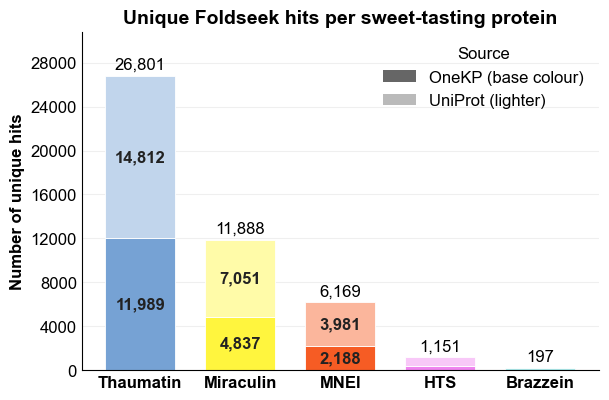

In [10]:
width_pt = 450
height_pt = 300
PT_TO_IN = 1 / 72

import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
#    "svg.fonttype": "none",  # Keep text editable in Illustrator.
})

# Count each target once per cleaned query and source.
unique_hits_df = combined_hits_df.drop_duplicates(
    subset=["cleaned_query", "source", "target"]
)

# Rows = queries; columns = databases.
hit_counts = (
    unique_hits_df
    .groupby(["cleaned_query", "source"])["target"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=["OneKP", "UniProt"], fill_value=0)
)

# Order queries by total number of hits.
query_order = hit_counts.sum(axis=1).sort_values(ascending=False).index
hit_counts = hit_counts.loc[query_order]

# Display the counts in the notebook.
display(hit_counts.assign(Total=hit_counts.sum(axis=1)))

def lighten(color, amount=0.55):
    rgb = np.array(to_rgb(color))
    return tuple(rgb + (1 - rgb) * amount)

base_colors = [protein_colors[query] for query in hit_counts.index]
light_colors = [lighten(color) for color in base_colors]

fig, ax = plt.subplots(figsize=(width_pt / 72, height_pt / 72))
x = np.arange(len(hit_counts))

onekp_counts = hit_counts["OneKP"].to_numpy()
uniprot_counts = hit_counts["UniProt"].to_numpy()

onekp_bars = ax.bar(
    x,
    onekp_counts,
    color=base_colors,
    width=0.7,
    edgecolor="white",
    linewidth=0.6,
)

uniprot_bars = ax.bar(
    x,
    uniprot_counts,
    bottom=onekp_counts,
    color=light_colors,
    width=0.7,
    edgecolor="white",
    linewidth=0.6,
)

# Label only segments with more than 1,000 hits.
# Dark text is easier to read on yellow and pastel colours.
for container in (onekp_bars, uniprot_bars):
    ax.bar_label(
        container,
        labels=[
            f"{int(bar.get_height()):,}" if bar.get_height() > 1000 else ""
            for bar in container
        ],
        label_type="center",
        fontsize=12,
        color="#222222",
        fontweight="bold",
    )

# Total counts above each bar.
totals = hit_counts.sum(axis=1)
for position, total in zip(x, totals):
    ax.annotate(
        f"{total:,}",
        xy=(position, total),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=12,
    )

ax.set_xticks(x)

ax.set_xticklabels(hit_counts.index, fontsize=12, fontweight="bold")
ax.set_title("Unique Foldseek hits per sweet-tasting protein", fontsize=14, fontweight="bold")
ax.set_ylabel("Number of unique hits", fontsize=12, fontweight="bold")

# Remove tick marks
ax.tick_params(axis="x", which="both", length=0)
ax.tick_params(axis="y", which="both", length=0)
ax.set_xticklabels(hit_counts.index, fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("Number of unique hits")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(0, max(totals.max() * 1.15, 1))

# Neutral swatches illustrate the source shading convention.
ax.legend(
    handles=[
        Patch(facecolor="#666666", label="OneKP (base colour)"),
        Patch(facecolor=lighten("#666666"), label="UniProt (lighter)"),
    ],
    title="Source",
    frameon=False,
)

ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

from matplotlib.text import Text

for text in fig.findobj(match=Text):
    if text.get_fontsize() < 12:
        text.set_fontsize(12)

fig.savefig(
    "unique_hits_per_query.svg",
    bbox_inches="tight",
    transparent=True,
)
plt.show()